### Cell 01 | 06 — Independent two-hour strain-rate scaling inversion

Run notebook 05 first. Reuse its DDM unit responses with **zero new DDM solves**. Fit rate profiles only, independently in all 114 windows:

`observed_rate[:, i] ≈ c_tensile[i]*baseline_tensile_rate[:, i] + c_shear[i]*baseline_shear_rate[:, i]`.

Before T2 only tensile is active. Both fixed planes remain unchanged. Rank and normalized condition numbers are checked and exported. Strain is validation only.

The default is signed least squares (`NONNEGATIVE_RATE_SCALES=False`): closing or reverse shear is allowed, not silently clipped. Set this option to True for nonnegative coefficients. The global baseline still uses nonnegative amplitudes. There is no monotonicity or temporal smoothing constraint.

Within each window, multiply the baseline **slip rate** by its fitted coefficient and integrate exactly, carrying the boundary slip into the next window. This produces continuous slip, although slip rate can jump at window boundaries. Do not multiply cumulative baseline slip by a time-dependent rate coefficient: that would give inconsistent rates. Within-window baseline rate shapes are an explicit assumption, not sub-two-hour resolution inferred from data.

Slip starts at zero at T1 by convention; absolute initial slip is not measured by DAS. Predicted strain is referenced to its first two-hour mean. Rate noise and common-mode drift can accumulate in slip/strain. All component slip, rate and strain profiles are exported separately, along with fit metrics for both objectives when available. No uncertainty or fracture uniqueness is claimed.

### Revision record (append-only)

**2026-09-20 22:24:23 MDT** — reorganized every code section into a numbered title/introduction followed by numbered code; doubled plot typography; added recorded pressure-stage labels, stronger paired profile overlays and simulated-waterfall summaries. Created this two-hour rate-fitting notebook with 114 windows and separate output files; inherited earlier history describes its four-hour source.

**2026-09-20 22:28:05 MDT** — remove stage underline collisions; verify equal-height geometry rows; add same-observation rate comparison in notebook 06.

**2026-09-20 22:29:10 MDT** — retain physically equal aspect ratios in geometry views; audit common row edges with an explicit column-width exemption.

**2026-09-20 22:37:10 MDT** — user clarification: the Markdown title/introduction and following code cell share the same number; section numbers advance once per pair. Numerical code and executed results are unchanged.

**2026-09-21 12:06:18 MDT** — corrected comparison-table labels for existing four-hour results before approved publication of notebooks 05/06. No fitted values or figures changed.

### Cell 02 | Run instructions, environment and revision record

Revision: **2026-09-20 18:53:13 MDT**. Each title/introduction and its following code cell share one section number. Every code cell starts with its modification timestamp; retain older entries in this section for future changes.

Revision history: **2026-09-19 23:52 MDT** — initial two-step implementation, restored raw observations, mesh and derivative checks, sign-preserving sub-window reconstruction. **2026-09-20 17:19:01 MDT** — final figure review: move plane annotations and pressure legend out of the data, separate 3D labels, and retain the tested numerical model unchanged. **2026-09-20 18:53:13 MDT** — number all cells; share bottom-only date/time axes; update color limits; add pressure/slip figures and the separate strain-rate fitting pair.

1. Keep this project folder beside the existing `V1_DDM` folder in the local Fervo code tree.
2. Use the Python environment that runs the existing DDM notebooks. Restart the kernel and Run All in **01 → 02** for strain fitting, or **03 → 04** for four-hour strain-rate fitting, or **05 → 06** for two-hour strain-rate fitting. Each inversion notebook performs **zero DDM solves**. The rate pair can run without running the strain pair first.
3. Strain-fit results are written to `output/`; four-hour rate-fit results to `output/rate_fit/`; two-hour rate-fit results to `output/rate_fit_2h/`. Observations and fixed unit responses are shared. The private GitHub repository tracks only the six notebook sources via Git commit/push, with generated cell outputs cleared from publication copies. Raw DAS, microseismic, pressure data and generated results remain local.

Dependencies used on this machine: Python 3.14, NumPy 2.5.3, SciPy 1.18.1, pandas 3.0.5, Matplotlib 3.11.2, Plotly 7.0.0, nbformat 5.11.1, nbclient 0.11.0 and ipykernel 7.3.0; macOS 15.7.9 x86_64. Each run writes actual versions to its JSON report. Other systems are unverified.

Notebooks 01, 03 and 05 reuse the local `V1_DDM/ddm_backend.py` pinned DDMpy adapter and geometry diagnostics, plus their existing local dependencies (including JIN_pylib). This is a private, local-data research workflow, **not a standalone public distribution**. Original DDMpy provenance is retained in the generated report. No third-party code is relicensed or published here.

Selected documentation scope: source comments and environment/run notes. README/report metadata, a redistributable example, separate requirements file and licensing review are **out of scope**, per the notebook-source-only repository requirement; this is not a claim of full CWP compliance.

Time is fixed UTC−7, not daylight-saving-aware local time. All input events are in **2025**. T3 is **2025-03-06 00:00**; the 2026 date in the request is treated as a year typo. T1 is February 24 at 12:00 and T2 is February 28 at 00:00.

### Observation and plotting conventions

- Native DAS rate is in nanostrain/s, strain in millistrain, MD and DDM geometry in ft; slip exports are in mm. There are 114 two-hour windows, represented by their **center** times. Each profile is a sample mean, not an instantaneous profile.
- The verified early cache is retained. The late interval is rebuilt from actual March raw files with the established 3×7 median filter and common-mode subtraction, and must reproduce the overlapping cache. Raw file times are UTC; subtract seven hours exactly once.
- Integrate only valid adjacent samples, retaining the cumulative offset after gaps. Missing increments are not inferred; acquisition gaps remain masked. Subtract the first two-hour mean strain profile once. This deliberately replaces the older reset-to-zero-after-each-gap integration, which is incompatible with interpreting an independent fit as one continuous slip history.
- Waterfall backgrounds use **10-minute sample means** for display only. Inversion and two-hour overlays use all native samples. Small MD is at the top, large MD at the bottom. All rate panels share ±0.3 nanostrain/s and all strain panels share ±0.15 millistrain. Gray means missing, not zero. Black solid profiles are observations; green dashed profiles are models; both share one wiggle scale for each quantity. Linked time axes show ticks and labels only at the bottom: month/day/year on line 1, hour:minute on line 2. A separate two-panel pressure/slip figure uses the same convention.
- The upper curves are injection-well **pressure**, not volumetric injection rate. No flow-rate record is relabeled as pressure or vice versa.
- These are exploratory fit diagnostics. Improved training residuals do not establish fracture uniqueness, geomechanical causality or uncertainty bounds. Depth samples and integrated strain are correlated; unweighted least squares is not a statistical likelihood model.

### Current figure and fitting notes

The figures test how the inferred slip history reproduces measured depth profiles in the context of recorded injection pressure. Pressure is context, the rate waterfall shows rate agreement, and strain shows cumulative consistency; these fits do not establish causation. The quantitative grid uses Python/Matplotlib and exports editable PDF/SVG plus 300 dpi PNG. All observations are retained on their existing support.

The pressure band uses **STAGENUMBER from the input records**, split into contiguous runs (repeated numbers are not merged). The three gauge files must agree before a shared stage band is drawn. A band is metadata, not an inference of pumping-well identity. Black observed lines and thicker dashed green simulated lines use identical offsets and a thin white contrast outline. Each figure includes a profile legend.

**2026-09-20 22:24:23 MDT** — reorganized every code section into a numbered title/introduction followed by numbered code; doubled plot typography; added recorded pressure-stage labels, stronger paired profile overlays and simulated-waterfall summaries. Created this two-hour rate-fitting notebook with 114 windows and separate output files; inherited earlier history describes its four-hour source.

### Cell 03 | Imports, paths and plotting settings

Load dependencies, choose the fitting objective and window length, and set text sizes to at least twice the previous values.

In [1]:
# Cell 03 | Modified 2026-09-20 22:37:10 MDT — Imports, paths and plotting settings
# Purpose: Load dependencies, choose the fitting objective and window length, and set text sizes to at least twice the previous values.
from pathlib import Path
import hashlib
import json
import platform
import sys
import warnings
import os
# Modified 2026-09-19 23:34 MDT — keep the Matplotlib cache inside the local project.
_mpl_cache=Path.cwd()/'output/.matplotlib'
_mpl_cache.mkdir(parents=True,exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR',str(_mpl_cache))
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import nnls
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import matplotlib.patheffects as patheffects

PROJECT = Path.cwd()
V1 = PROJECT.parent/'V1_DDM'
if PROJECT.name == 'two_step_staging':
    V1 = PROJECT.parent
# Modified 2026-09-20 — isolate strain/rate fits while sharing immutable observations.
FIT_TARGET = 'rate'  # The rate-fit notebooks set this to 'rate'.
TARGET_INDEX = {'rate':0,'strain':1}[FIT_TARGET]
DATA_OUT = PROJECT/'output'
WINDOW_HOURS = 2
OUT = DATA_OUT if FIT_TARGET=='strain' else DATA_OUT/('rate_fit' if WINDOW_HOURS==4 else 'rate_fit_2h')
OUT.mkdir(parents=True,exist_ok=True)
T1, T2, T3 = map(pd.Timestamp, ['2025-02-24 12:00','2025-02-28 00:00','2025-03-06 00:00'])
EDGES = pd.date_range(T1,T3,freq=f'{WINDOW_HOURS}h').as_unit('ns')
CENTERS = EDGES[:-1]+pd.Timedelta(hours=WINDOW_HOURS/2)
FT_TO_MM = 304.8
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':20,'axes.titlesize':24,'axes.labelsize':20,'xtick.labelsize':20,'ytick.labelsize':20,'legend.fontsize':20,'figure.titlesize':24,'pdf.fonttype':42,'svg.fonttype':'none'})

### Cell 04 | Observation support and mean profiles

Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.

In [2]:
# Cell 04 | Modified 2026-09-20 22:37:10 MDT — Observation support and mean profiles
# Purpose: Average every native sample within each fitting window. Integrate valid adjacent rates and preserve missing-data masks.
def profiles(values, time, mask=None):
    """Return depth-by-window sample means on the supplied observation support."""
    values = np.asarray(values,float)
    if mask is not None:
        values = np.where(mask,values,np.nan)
    result=[]
    for lo,hi in zip(EDGES[:-1],EDGES[1:]):
        chunk=values[..., (time>=lo)&(time<hi)]
        count=np.isfinite(chunk).sum(axis=-1)
        result.append(np.divide(np.nansum(chunk,axis=-1),count,out=np.full(count.shape,np.nan),where=count>0))
    return np.stack(result,axis=-1)


def integrate_observed(rate,time):
    """Integrate valid adjacent rates to millistrain; hold offset, do not bridge gaps."""
    dt=np.diff(time.asi8)/1e9
    valid=np.isfinite(rate)
    increments=(rate[:,:-1]+rate[:,1:])*.5*dt/1e6
    increments=np.where(valid[:,:-1]&valid[:,1:]&(dt[None,:]<=20),increments,0.)
    strain=np.column_stack([np.zeros(len(rate)),np.cumsum(increments,axis=1)])
    strain[~valid]=np.nan
    strain-=profiles(strain,time)[:,[0]]
    return strain


def load_observations():
    """Return saved rate, cumulative strain, depths, time, support and 2-hour profiles."""
    with np.load(DATA_OUT/'observations_through_20250306.npz') as z:
        rate,depth,time=z['rate'],z['depth'],pd.DatetimeIndex(z['time_ns'])
    strain=integrate_observed(rate,time)
    support=np.isfinite(rate)
    assert np.all(support==support[[0]]), 'Partial-depth gaps require depth-specific slip averaging.'
    assert time.is_monotonic_increasing and not time.has_duplicates
    return dict(rate=rate,strain=strain,depth=depth,time=time,support=support,
                profiles=np.stack([profiles(rate,time),profiles(strain,time)]))

### Cell 05 | Forward model and residual metrics

Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.

In [3]:
# Cell 05 | Modified 2026-09-20 22:37:10 MDT — Forward model and residual metrics
# Purpose: Define the prescribed time laws, convert component slip to strain/rate, and score the predicted profiles.
def time_laws(time):
    """Return three unit-amplitude time laws and analytic derivatives per second."""
    t=pd.DatetimeIndex(time)
    d1,d2=(T2-T1).total_seconds(),(T3-T2).total_seconds()
    x=np.clip((t-T1).total_seconds().to_numpy()/d1,0,1)
    y=np.clip((t-T2).total_seconds().to_numpy()/d2,0,1)
    laws=np.array([x*x,y,y*y])
    speeds=np.array([np.where((t>=T1)&(t<T2),2*x/d1,0),
                     np.where((t>=T2)&(t<=T3),1/d2,0),
                     np.where((t>=T2)&(t<=T3),2*y/d2,0)])
    return laws,speeds


def forward_components(unit,amounts,speeds,obs,reference=None):
    """Map signed slips/speeds in mm to component strain and rate, with one reference."""
    strain=unit[:,:,None]*amounts[:,None,:]/FT_TO_MM*1e3
    rate=unit[:,:,None]*speeds[:,None,:]/FT_TO_MM*1e9
    if reference is None:
        reference=profiles(amounts,obs['time'],obs['support'][[0]])[:,0]
    strain-=unit[:,:,None]*reference[:,None,None]/FT_TO_MM*1e3
    pp=np.stack([profiles(rate,obs['time'],obs['support']),profiles(strain,obs['time'],obs['support'])],axis=1)
    return dict(amounts=amounts,speeds=speeds,rate=rate,strain=strain,profiles=pp,reference=reference)


def fit_metrics(obs,model):
    """Return unweighted profile RMSE and target-RMS-normalized RMSE for both quantities."""
    rows=[]
    for q,(name,units) in enumerate([('rate','nanostrain/s'),('strain','millistrain')]):
        y=obs['profiles'][q]; pred=model['profiles'][:,q].sum(axis=0)
        mask=np.isfinite(y)&np.isfinite(pred)
        if q==1: mask[:,0]=False
        rmse=np.sqrt(np.mean((pred[mask]-y[mask])**2))
        rows.append(dict(quantity=name,units=units,rmse=float(rmse),relative_rmse=float(rmse/np.sqrt(np.mean(y[mask]**2))),samples=int(mask.sum()),fitted=q==TARGET_INDEX))
    return pd.DataFrame(rows)

### Cell 06 | Injection pressure and figure exports

Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.

In [4]:
# Cell 06 | Modified 2026-09-20 22:37:10 MDT — Injection pressure and figure exports
# Modified 2026-09-20 22:29:10 MDT — document physical-aspect geometry column exemption.
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Load recorded hydraulic-stage numbers and save local figures with shared-axis alignment checks.
def pressure_data():
    """Read three local injection-well pressure records; return an unshifted MST table."""
    root=V1.parents[2]/'Aleksei/Data/Bearskin Stimulation Data'
    frames=[]
    for well,color in [('1-IA','#E69F00'),('3-PA','#7B3294'),('4-PB','#D55E00')]:
        frame=pd.read_csv(root/f'Bearskin {well} Pressure.csv')
        frame['time']=pd.to_datetime(frame.MSTTIMESTAMP)
        frame['stage_number']=pd.to_numeric(frame.STAGENUMBER,errors='coerce')
        frame['pressure_psi']=pd.to_numeric(frame.PRESSURE_PSI,errors='coerce')
        frame=frame.loc[frame.time.between(T1,T3)].copy()
        frame['well']='Bearskin '+well; frame['color']=color
        frames.append(frame[['time','pressure_psi','well','color','stage_number']])
    return pd.concat(frames,ignore_index=True)


def save_figure(fig,name,axes=None):
    """Save PNG/PDF plus measured axes rectangles; reject inconsistent shared x extents."""
    fig.canvas.draw()
    boxes=[]
    for ax in (axes or []):
        box=ax.get_position()
        boxes.append(dict(left_pt=box.x0*fig.get_figwidth()*72,right_pt=box.x1*fig.get_figwidth()*72,bottom_pt=box.y0*fig.get_figheight()*72,top_pt=box.y1*fig.get_figheight()*72))
    if len(boxes)>1:
        assert np.ptp([b['left_pt'] for b in boxes])<1.5
        assert np.ptp([b['right_pt'] for b in boxes])<1.5
        # Optional local figure QA; not a dependency for normal notebook execution.
        qa_scripts=os.environ.get('FERVO_FIGURE_QA_SCRIPTS')
        if qa_scripts:
            if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
            from audit_panel_alignment import require_matplotlib_panel_alignment
            require_matplotlib_panel_alignment(fig,axes=axes,json_out=OUT/f'{name}_alignment.json',strict=True)
    if axes is None and len(fig.axes)>=4 and os.environ.get('FERVO_FIGURE_QA_SCRIPTS'):
        qa_scripts=os.environ['FERVO_FIGURE_QA_SCRIPTS']
        if qa_scripts not in sys.path: sys.path.insert(0,qa_scripts)
        from audit_panel_alignment import require_matplotlib_panel_alignment
        # Equal-aspect physical projections intentionally differ in width; compare row edges.
        require_matplotlib_panel_alignment(fig,axes=fig.axes[:4],panel_ids=['a','b','c','d'],
            row_groups=[['a','b'],['c','d']],column_groups=[],
            exemptions=[{'panels':['a','b','c','d'],'checks':['column'],
                         'reason':'Equal physical aspect ratios in XY/XZ/YZ and a 3D view require different widths; row heights and edges remain comparable.'}],
            json_out=OUT/f'{name}_alignment.json',strict=True)
    (OUT/f'{name}_layout.json').write_text(json.dumps(boxes,indent=2))
    fig.savefig(OUT/f'{name}.png',dpi=300)
    fig.savefig(OUT/f'{name}.pdf',dpi=300)
    fig.savefig(OUT/f'{name}.svg',dpi=300)
    display(fig)
    plt.close(fig)

### Cell 07 | Visible waterfall profiles

Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.

In [5]:
# Cell 07 | Modified 2026-09-20 22:37:10 MDT — Visible waterfall profiles
# Purpose: Overlay all observed profiles in black and simulated profiles in thicker dashed green, with a common amplitude scale and legend.
def profile_legend(fig, y=.985):
    """Use one figure-level key for the paired profile curves."""
    handles=[Line2D([],[],color='black',lw=1.6,label='Observed profile'),
             Line2D([],[],color='#00852B',lw=2.4,ls='--',label='Simulated profile')]
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,y),ncol=2,frameon=False)


def waterfall(ax,obs,model,quantity,background='observed',scale=None):
    """Draw a waterfall and every fitted window profile at its center time."""
    key=('rate','strain')[quantity]
    values=obs[key] if background=='observed' else model[key].sum(axis=0)
    values=np.where(obs['support'],values,np.nan)
    # Display-only 10-minute means; profile fitting retains all native samples.
    frame=pd.DataFrame(values.T,index=obs['time']).resample('10min').mean()
    cmap=plt.get_cmap('seismic').copy(); cmap.set_bad('#bbbbbb')
    lim=(.3,.15)[quantity]
    image=ax.pcolormesh(frame.index,obs['depth'],frame.to_numpy().T,cmap=cmap,vmin=-lim,vmax=lim,shading='auto',rasterized=True)
    observed=obs['profiles'][quantity]; simulated=model['profiles'][:,quantity].sum(axis=0)
    if scale is None:
        scale=max(np.nanpercentile(np.abs(np.r_[observed.ravel(),simulated.ravel()]),98),1e-12)
    # A common amplitude-to-time mapping for observed/simulated; halve spacing at 2 h.
    width_days=.055*(WINDOW_HOURS/4)/scale
    x=mdates.date2num(CENTERS)
    for j,anchor in enumerate(x):
        ax.plot(anchor+observed[:,j]*width_days,obs['depth'],color='black',lw=1.6,zorder=5,
                path_effects=[patheffects.Stroke(linewidth=2.8,foreground='white'),patheffects.Normal()])
        ax.plot(anchor+simulated[:,j]*width_days,obs['depth'],color='#00852B',ls='--',lw=2.4,zorder=6,
                path_effects=[patheffects.Stroke(linewidth=3.5,foreground='white'),patheffects.Normal()])
    ax.set(ylim=(10500,10200),xlim=(T1,T3),ylabel='Measured depth (ft)')
    ax.set_title(f'{background.capitalize()} {key} waterfall | {WINDOW_HOURS}-hour mean profiles',pad=48)
    for t,label in [(T1,'T1'),(T2,'T2'),(T3,'T3')]:
        ax.axvline(t,color='#B36B00',ls='--',lw=1.2)
        ax.text(t,1.012,label,transform=ax.get_xaxis_transform(),color='#996000',fontsize=16,ha='center',va='bottom')
    geometry_file=OUT/'fixed_plane_geometry.csv'
    if geometry_file.exists():
        for k,row in pd.read_csv(geometry_file).iterrows():
            color=['#B36B00','teal'][k]
            ax.axhline(row.plane_crossing_md_ft,color=color,ls='--',lw=1.2)
            ax.annotate(f'F{k+1} plane extension: {row.plane_crossing_md_ft:.1f} ft',xy=(.13+.43*k,1),xycoords='axes fraction',xytext=(0,10),textcoords='offset points',ha='left',va='bottom',fontsize=16,color=color)
    return image

### Cell 08 | Pressure, slip and shared time axes

Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.

In [6]:
# Cell 08 | Modified 2026-09-20 22:37:10 MDT — Pressure, slip and shared time axes
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Label contiguous recorded stage intervals above the pressure curves and align pressure and continuous slip histories.
def pressure_slip_panels(axes,obs,model,injection,title):
    """Plot recorded pressure/stage metadata and continuous tensile/shear slip."""
    for well,frame in injection.groupby('well',sort=False):
        axes[0].plot(frame.time,frame.pressure_psi,lw=1.5,color=frame.color.iloc[0],label=well)
    # The supplied files repeat the same stage timeline across all three gauges.
    # Check that agreement before drawing a shared band; never infer stages from peaks.
    stage_table=injection.pivot(index='time',columns='well',values='stage_number').sort_index()
    assert stage_table.nunique(axis=1,dropna=False).max()==1, 'Gauge stage records disagree.'
    stage=stage_table.iloc[:,0]
    changes=stage.ne(stage.shift()) & ~(stage.isna() & stage.shift().isna())
    runs=[]
    for _,part in stage.groupby(changes.cumsum()):
        if part.notna().any():
            runs.append((part.index[0],part.index[-1],int(part.iloc[0])))
    max_pressure=float(injection.pressure_psi.max())
    axes[0].set_ylim(0,max_pressure*1.50)
    for i,(lo,hi,number) in enumerate(runs):
        center=lo+(hi-lo)/2
        # Two alternating lanes avoid collisions between adjacent short stages.
        level=max_pressure*(1.19+.18*(i%2))
        axes[0].text(center,level,str(number),ha='center',va='center',fontsize=18)
    axes[0].set(ylabel='Injection pressure (psi)')
    axes[0].set_title('Injection pressure | recorded stage numbers above curves',pad=60)
    axes[0].legend(ncol=3,fontsize=20,loc='lower left',bbox_to_anchor=(0,1.015),borderaxespad=0,frameon=False)
    twin=axes[1].twinx()
    axes[1].plot(obs['time'],model['amounts'][0],color='royalblue',lw=2,label='Tensile opening')
    twin.plot(obs['time'],np.abs(model['amounts'][1]),color='firebrick',lw=2,label='Shear magnitude')
    axes[1].set(ylabel='Tensile slip (mm)')
    axes[1].set_title(title,pad=58)
    twin.set_ylabel('|Shear slip| (mm)',color='firebrick')
    axes[1].yaxis.label.set_color('royalblue')
    axes[1].legend(handles=[Line2D([],[],color='royalblue',label='Tensile'),Line2D([],[],color='firebrick',label='|Shear|')],loc='lower left',bbox_to_anchor=(0,1.01),ncol=2,frameon=False)
    for ax in axes[:2]: ax.axvline(T2,color='#B36B00',ls='--',lw=1.2)
    return twin


def shared_time_axis(axes):
    """Show date/time ticks only on the bottom shared axis, in fixed UTC−7."""
    for ax in axes: ax.set_xlim(T1,T3)
    axes[-1].xaxis.set_major_locator(mdates.DayLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y\n%H:%M'))
    for ax in axes[:-1]:
        assert ax.get_shared_x_axes().joined(ax,axes[-1])
        ax.tick_params(axis='x',which='both',bottom=False,top=False,labelbottom=False,labeltop=False)
        ax.set_xlabel('')
    axes[-1].tick_params(axis='x',which='both',bottom=True,labelbottom=True,top=False,labeltop=False)
    axes[-1].set_xlabel('Time (fixed UTC−7)')

### Cell 09 | Diagnostic figure layouts

Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.

In [7]:
# Cell 09 | Modified 2026-09-20 22:37:10 MDT — Diagnostic figure layouts
# Purpose: Create pressure/slip figures and combined observed or simulated waterfall figures with enlarged labels.
def plot_pressure_slip(obs,model,injection,name):
    """Save pressure with recorded stages and slip, sharing one time axis."""
    fig,axes=plt.subplots(2,1,figsize=(30,11),sharex=True)
    fig.subplots_adjust(left=.075,right=.90,bottom=.13,top=.84,hspace=.65)
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    shared_time_axis(axes)
    save_figure(fig,f'{name}_pressure_slip',list(axes))
    return fig


def plot_summary(obs,model,injection,name,background='observed'):
    """Align pressure, slip, and two diagnostic waterfalls on one timeline."""
    fig=plt.figure(figsize=(30,22))
    gs=fig.add_gridspec(4,2,height_ratios=[1.25,1,2.3,2.3],width_ratios=[1,.016],left=.075,right=.91,bottom=.065,top=.87,hspace=.62,wspace=.06)
    axes=[fig.add_subplot(gs[0,0])]
    axes.extend(fig.add_subplot(gs[i,0],sharex=axes[0]) for i in range(1,4))
    pressure_slip_panels(axes,obs,model,injection,'Tensile and shear slip history')
    for q,ax in enumerate(axes[2:]):
        im=waterfall(ax,obs,model,q,background=background)
        fig.colorbar(im,cax=fig.add_subplot(gs[q+2,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
    profile_legend(fig,y=.98)
    shared_time_axis(axes)
    suffix='' if background=='observed' else '_simulated_summary'
    save_figure(fig,name+suffix,axes)
    return fig


def plot_comparison(obs,model,name):
    """Compare observed/simulated waterfalls with the same color and wiggle scales."""
    for background in ['observed','simulated']:
        fig=plt.figure(figsize=(30,15))
        gs=fig.add_gridspec(2,2,width_ratios=[1,.016],left=.075,right=.91,bottom=.105,top=.85,hspace=.40,wspace=.06)
        axes=[]
        for q in range(2):
            ax=fig.add_subplot(gs[q,0],sharex=axes[0] if axes else None); axes.append(ax)
            im=waterfall(ax,obs,model,q,background)
            fig.colorbar(im,cax=fig.add_subplot(gs[q,1]),label=('Rate (nanostrain/s)','Strain (millistrain)')[q])
        profile_legend(fig,y=.98)
        shared_time_axis(axes)
        save_figure(fig,f'{name}_{background}',axes)

### Cell 10 | Component tables and runtime provenance

Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.

In [8]:
# Cell 10 | Modified 2026-09-20 22:37:10 MDT — Component tables and runtime provenance
# Purpose: Export per-window component slips, strain and rate profiles, residual metrics, and actual dependency versions.
def export_components(obs,model,prefix,coefficients=None):
    """Write per-component, per-2h slip, strain and strain-rate CSVs and a compact NPZ."""
    mean_amount=profiles(model['amounts'],obs['time'],obs['support'][[0]])
    mean_speed=profiles(model['speeds'],obs['time'],obs['support'][[0]])
    for k,component in enumerate(['tensile','shear']):
        slips=pd.DataFrame({'window_start':EDGES[:-1],'window_end':EDGES[1:],'center_time':CENTERS,'mean_signed_slip_mm':mean_amount[k],'mean_absolute_slip_mm':np.abs(mean_amount[k]),'mean_signed_slip_rate_mm_s':mean_speed[k]})
        if coefficients is not None: slips[f'{FIT_TARGET}_baseline_scale']=coefficients[k]
        slips.to_csv(OUT/f'{prefix}_{component}_slip_2h.csv',index=False)
        frame=pd.DataFrame({'center_time':np.repeat(CENTERS,len(obs['depth'])),'md_ft':np.tile(obs['depth'],len(CENTERS)),
            'strain_millistrain':model['profiles'][k,1].T.ravel(),'strain_rate_nanostrain_s':model['profiles'][k,0].T.ravel()})
        frame.to_csv(OUT/f'{prefix}_{component}_profiles_2h.csv',index=False)
    np.savez_compressed(OUT/f'{prefix}_profiles_2h.npz',depth_ft=obs['depth'],centers_ns=CENTERS.asi8,
                        component_profiles=model['profiles'],mean_slip_mm=mean_amount,mean_slip_rate_mm_s=mean_speed,observed_profiles=obs['profiles'])
    fit_metrics(obs,model).to_csv(OUT/f'{prefix}_metrics.csv',index=False)


def environment_report():
    """Return actual runtime and dependency versions; no claims about untested platforms."""
    return dict(system=platform.platform(),python=sys.version.split()[0],numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)

### Cell 11 | Load the rate-fitted baseline; no DDM computation

Load the matching baseline and verify depth/time arrays and reconstructed profiles before inversion.

In [9]:
# Cell 11 | Modified 2026-09-20 22:37:10 MDT — Load the rate-fitted baseline; no DDM computation
# Purpose: Load the matching baseline and verify depth/time arrays and reconstructed profiles before inversion.
obs=load_observations()
with np.load(OUT/'baseline_for_inversion.npz') as z:
    unit=z['unit']; amplitudes=z['amplitudes']; base_amount=z['amounts']; base_speed=z['speeds']
    base_profiles=z['component_profiles']; base_reference=z['reference_mm']
    np.testing.assert_array_equal(z['time_ns'],obs['time'].asi8)
    np.testing.assert_array_equal(z['depth'],obs['depth'])
baseline=forward_components(unit,base_amount,base_speed,obs,reference=base_reference)
np.testing.assert_allclose(baseline['profiles'],base_profiles,atol=1e-12)
# Signed rates permit opening/closing or slip-direction reversal; switch to True to forbid them.
NONNEGATIVE_RATE_SCALES=False

### Cell 12 | Independently fit each two-hour strain-rate profile

Fit independent tensile/shear coefficients in each window and verify reconstruction, identifiability, slip continuity and rate consistency.

In [10]:
# Cell 12 | Modified 2026-09-20 22:37:10 MDT — Independently fit each two-hour strain-rate profile
# Purpose: Fit independent tensile/shear coefficients in each window and verify reconstruction, identifiability, slip continuity and rate consistency.
scales=np.zeros((2,len(CENTERS)))
diagnostics=[]
for j,t in enumerate(CENTERS):
    active=[0] if t<T2 else [0,1]
    y=obs['profiles'][0,:,j]
    columns=base_profiles[active,0,:,j].T
    valid=np.isfinite(y)&np.isfinite(columns).all(axis=1)
    if valid.sum()<len(active):
        raise ValueError(f'Insufficient observations at {t}; do not replace with extrapolated coefficients.')
    norms=np.linalg.norm(columns[valid],axis=0)
    if np.any(norms<1e-14):
        raise ValueError(f'Zero baseline rate at {t}; its multiplicative scale is unidentifiable.')
    scaled=columns[valid]/norms
    rank=np.linalg.matrix_rank(scaled)
    assert rank==len(active),f'Rank-deficient rate fit at {t}'
    if NONNEGATIVE_RATE_SCALES:
        normalized,_=nnls(scaled,y[valid])
    else:
        normalized=np.linalg.lstsq(scaled,y[valid],rcond=None)[0]
    scales[active,j]=normalized/norms
    diagnostics.append(dict(center_time=t,rank=int(rank),condition=float(np.linalg.cond(scaled)),
        finite_depths=int(valid.sum()),constraint='nonnegative' if NONNEGATIVE_RATE_SCALES else 'signed'))
diagnostics=pd.DataFrame(diagnostics)
display(diagnostics.tail())


def integrate_scaled_baseline_rates(scales,amplitudes,time):
    """Return continuous slip, slip rate and boundary slips from piecewise rate scales.

    Within window j, velocity=c[j]*baseline_velocity. Its exact integral is
    accumulated at the boundary, so changing c cannot create a displacement jump.
    All slips start at zero at T1; absolute initial slip is not measured by DAS.
    """
    laws,derivatives=time_laws(time)
    knot_laws,_=time_laws(EDGES)
    base=np.stack([amplitudes[0]*laws[0]+amplitudes[1]*laws[1],-amplitudes[2]*laws[2]])
    velocity=np.stack([amplitudes[0]*derivatives[0]+amplitudes[1]*derivatives[1],-amplitudes[2]*derivatives[2]])
    knots=np.stack([amplitudes[0]*knot_laws[0]+amplitudes[1]*knot_laws[1],-amplitudes[2]*knot_laws[2]])
    boundaries=np.zeros((2,len(EDGES)))
    amounts=np.empty_like(base); speeds=np.empty_like(base)
    for j,(lo,hi) in enumerate(zip(EDGES[:-1],EDGES[1:])):
        use=(time>=lo)&(time<hi)
        amounts[:,use]=boundaries[:,[j]]+scales[:,[j]]*(base[:,use]-knots[:,[j]])
        speeds[:,use]=scales[:,[j]]*velocity[:,use]
        boundaries[:,j+1]=boundaries[:,j]+scales[:,j]*(knots[:,j+1]-knots[:,j])
    return amounts,speeds,boundaries,knots


amounts,speeds,boundaries,base_knots=integrate_scaled_baseline_rates(scales,amplitudes,obs['time'])
final=forward_components(unit,amounts,speeds,obs)
# All 114 profiles, including the first window, are rate-fit targets.
np.testing.assert_allclose(final['profiles'][:,0],base_profiles[:,0]*scales[:,None,:],atol=1e-10)
np.testing.assert_allclose(np.diff(boundaries,axis=1),scales*np.diff(base_knots,axis=1),atol=1e-12)
assert np.all(amounts[1,obs['time']<T2]==0.)
assert np.all(speeds[1,obs['time']<T2]==0.)
seconds=(obs['time']-T1).total_seconds().to_numpy()
windows=np.searchsorted(EDGES.asi8,obs['time'].asi8,side='right')-1
interior=np.r_[False,(windows[:-2]==windows[1:-1])&(windows[1:-1]==windows[2:]),False]
np.testing.assert_allclose(np.gradient(amounts,seconds,axis=1,edge_order=2)[:,interior],speeds[:,interior],atol=1e-9)
baseline_metrics=fit_metrics(obs,baseline); final_metrics=fit_metrics(obs,final)
assert final_metrics.loc[0,'rmse']<=baseline_metrics.loc[0,'rmse']+1e-12
display(pd.concat({'rate baseline':baseline_metrics,'independent rate inversion':final_metrics}))

,center_time,rank,condition,finite_depths,constraint
109,2025-03-05 15:00:00,2,1.426075,44,signed
110,2025-03-05 17:00:00,2,1.426075,44,signed
111,2025-03-05 19:00:00,2,1.426075,44,signed
112,2025-03-05 21:00:00,2,1.426075,44,signed
113,2025-03-05 23:00:00,2,1.426075,44,signed


quantity         units      rmse  relative_rmse  \
rate baseline              0     rate  nanostrain/s  0.064533       0.703623   
                           1   strain   millistrain  0.010295       0.302739   
independent rate inversion 0     rate  nanostrain/s  0.037072       0.404206   
                           1   strain   millistrain  0.007554       0.222113   

                              samples  fitted  
rate baseline              0     5016    True  
                           1     4972   False  
independent rate inversion 0     5016    True  
                           1     4972   False

### Cell 13 | Export slip, rate, strain and a comparison of fitting objectives

Export component histories, fitted profiles and diagnostic metrics; keep fitting-window comparisons explicit.

In [11]:
# Cell 13 | Modified 2026-09-20 22:37:10 MDT — Export slip, rate, strain and a comparison of fitting objectives
# Modified 2026-09-21 12:06:18 MDT — label four-hour comparison inputs correctly; fitting unchanged.
# Modified 2026-09-20 22:28:05 MDT — refine rendered label clearance and verification.
# Purpose: Export component histories, fitted profiles and diagnostic metrics; keep fitting-window comparisons explicit.
export_components(obs,final,'inverted',scales)
pd.DataFrame({'time':EDGES,'tensile_mm':boundaries[0],'signed_shear_mm':boundaries[1],
    'shear_magnitude_mm':np.abs(boundaries[1])}).to_csv(OUT/'inverted_slip_knots_2h.csv',index=False)
pd.DataFrame({'window_start':EDGES[:-1],'window_end':EDGES[1:],'tensile_increment_mm':np.diff(boundaries[0]),
    'signed_shear_increment_mm':np.diff(boundaries[1])}).to_csv(OUT/'inverted_slip_increments_2h.csv',index=False)
pd.DataFrame({'center_time':CENTERS,'c_tensile_rate':scales[0],'c_shear_rate':scales[1]}).to_csv(OUT/'inversion_scaling_coefficients_2h.csv',index=False)
diagnostics.to_csv(OUT/'inversion_identifiability.csv',index=False)
np.savez_compressed(OUT/'inverted_history.npz',time_ns=obs['time'].asi8,amounts_mm=amounts,speeds_mm_s=speeds,
    scales=scales,boundary_slip_mm=boundaries,baseline_boundary_slip_mm=base_knots)
report={'objective':'Independent two-hour strain-rate profiles only; unweighted least squares.',
    'nonnegative_rate_scales':NONNEGATIVE_RATE_SCALES,'fixed_tensile_plane':True,'DDM_solves_in_this_notebook':0,
    'rate_definition':'Piecewise constant scale times baseline analytic slip rate; slip is its exact continuous integral, not c times cumulative baseline slip.',
    'reference':'Zero slip at T1 by convention; subtract the model first-window mean strain for strain diagnostics.',
    'max_two_column_condition':float(diagnostics.condition.max()),
    'baseline_rate_rmse':float(baseline_metrics.loc[0,'rmse']),'inverted_rate_rmse':float(final_metrics.loc[0,'rmse']),
    'negative_tensile_rate_windows':int(np.sum(scales[0]<0)),'reversed_shear_rate_windows':int(np.sum(scales[1]<0)),
    'environment':environment_report(),
    'caveat':'Strain is validation only. Rate noise/drift integrates into slip/strain; signed rate scales can imply closing or reverse shear. No monotonicity constraint or uncertainty estimate is imposed.'}
(OUT/'inversion_report.json').write_text(json.dumps(report,indent=2))
comparison_rows=[]
for objective,directory in [('strain_4h',DATA_OUT),('rate_4h',DATA_OUT/'rate_fit'),('rate_2h',OUT)]:
    for model in ['baseline','inverted']:
        path=directory/f'{model}_metrics.csv'
        if path.exists():
            frame=pd.read_csv(path)
            frame['fit_objective']=objective; frame['model']=model
            comparison_rows.append(frame)
comparison=pd.concat(comparison_rows,ignore_index=True)
comparison.to_csv(OUT/'strain_vs_rate_objectives.csv',index=False)
display(comparison[['fit_objective','model','quantity','rmse','relative_rmse']])
display(pd.read_csv(OUT/'inverted_tensile_slip_2h.csv').tail())
display(pd.read_csv(OUT/'inverted_shear_slip_2h.csv').tail())

# Compare both rate inversions on identical native observations and 2-hour targets.
# The 4-hour model is re-averaged on 2-hour windows; native RMSE has no averaging advantage.
four_hour_history=DATA_OUT/'rate_fit/inverted_history.npz'
if four_hour_history.exists():
    with np.load(four_hour_history) as previous:
        np.testing.assert_array_equal(previous['time_ns'],obs['time'].asi8)
        four_hour_rate=unit[:,:,None]*previous['speeds_mm_s'][:,None,:]/FT_TO_MM*1e9
    rows=[]
    for label,rate in [('4-hour',four_hour_rate.sum(axis=0)),('2-hour',final['rate'].sum(axis=0))]:
        valid=obs['support'] & np.isfinite(rate)
        model_profiles=profiles(rate,obs['time'],obs['support'])
        target=obs['profiles'][0]; good=np.isfinite(target)&np.isfinite(model_profiles)
        rows.append(dict(fitting_window=label,native_rate_rmse=float(np.sqrt(np.mean((rate[valid]-obs['rate'][valid])**2))),
            common_2h_profile_rmse=float(np.sqrt(np.mean((model_profiles[good]-target[good])**2))),
            native_samples=int(valid.sum()),profile_samples=int(good.sum()),units='nanostrain/s'))
    comparison=pd.DataFrame(rows)
    comparison.to_csv(OUT/'two_vs_four_hour_rate_validation.csv',index=False)
    display(comparison)
else:
    print('Run notebooks 03/04 to enable the optional same-support 2-hour versus 4-hour comparison.')

,fit_objective,model,quantity,rmse,relative_rmse
0,strain_4h,baseline,rate,0.063672,0.725521
1,strain_4h,baseline,strain,0.008066,0.236500
2,strain_4h,inverted,rate,0.036897,0.420433
3,strain_4h,inverted,strain,0.007558,0.221592
4,rate_4h,baseline,rate,0.058769,0.669646
5,rate_4h,baseline,strain,0.010313,0.302390
6,rate_4h,inverted,rate,0.033562,0.382424
7,rate_4h,inverted,strain,0.007581,0.222264
8,rate_2h,baseline,rate,0.064533,0.703623
9,rate_2h,baseline,strain,0.010295,0.302739


,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s,rate_baseline_scale
109,2025-03-05 14:00:00,2025-03-05 16:00:00,2025-03-05 15:00:00,6.600594,6.600594,0.000005,0.606039
110,2025-03-05 16:00:00,2025-03-05 18:00:00,2025-03-05 17:00:00,6.633378,6.633378,0.000004,0.445147
111,2025-03-05 18:00:00,2025-03-05 20:00:00,2025-03-05 19:00:00,6.652703,6.652703,0.000002,0.174300
112,2025-03-05 20:00:00,2025-03-05 22:00:00,2025-03-05 21:00:00,6.665798,6.665798,0.000002,0.245709
113,2025-03-05 22:00:00,2025-03-06 00:00:00,2025-03-05 23:00:00,6.680707,6.680707,0.000002,0.232406


,window_start,window_end,center_time,mean_signed_slip_mm,mean_absolute_slip_mm,mean_signed_slip_rate_mm_s,rate_baseline_scale
109,2025-03-05 14:00:00,2025-03-05 16:00:00,2025-03-05 15:00:00,-8.542897,8.542897,0.000018,-1.203373
110,2025-03-05 16:00:00,2025-03-05 18:00:00,2025-03-05 17:00:00,-8.437774,8.437774,0.000011,-0.744329
111,2025-03-05 18:00:00,2025-03-05 20:00:00,2025-03-05 19:00:00,-8.378407,8.378407,0.000005,-0.340213
112,2025-03-05 20:00:00,2025-03-05 22:00:00,2025-03-05 21:00:00,-8.341604,8.341604,0.000005,-0.321664
113,2025-03-05 22:00:00,2025-03-06 00:00:00,2025-03-05 23:00:00,-8.307562,8.307562,0.000004,-0.282010


,fitting_window,native_rate_rmse,common_2h_profile_rmse,native_samples,profile_samples,units
0,4-hour,0.107695,0.042832,3607780,5016,nanostrain/s
1,2-hour,0.105544,0.037072,3607780,5016,nanostrain/s


### Cell 14 | Shared-axis pressure, slip and waterfall diagnostics

Show recorded pressure stages and slip alongside observed and simulated strain-rate/strain waterfalls.

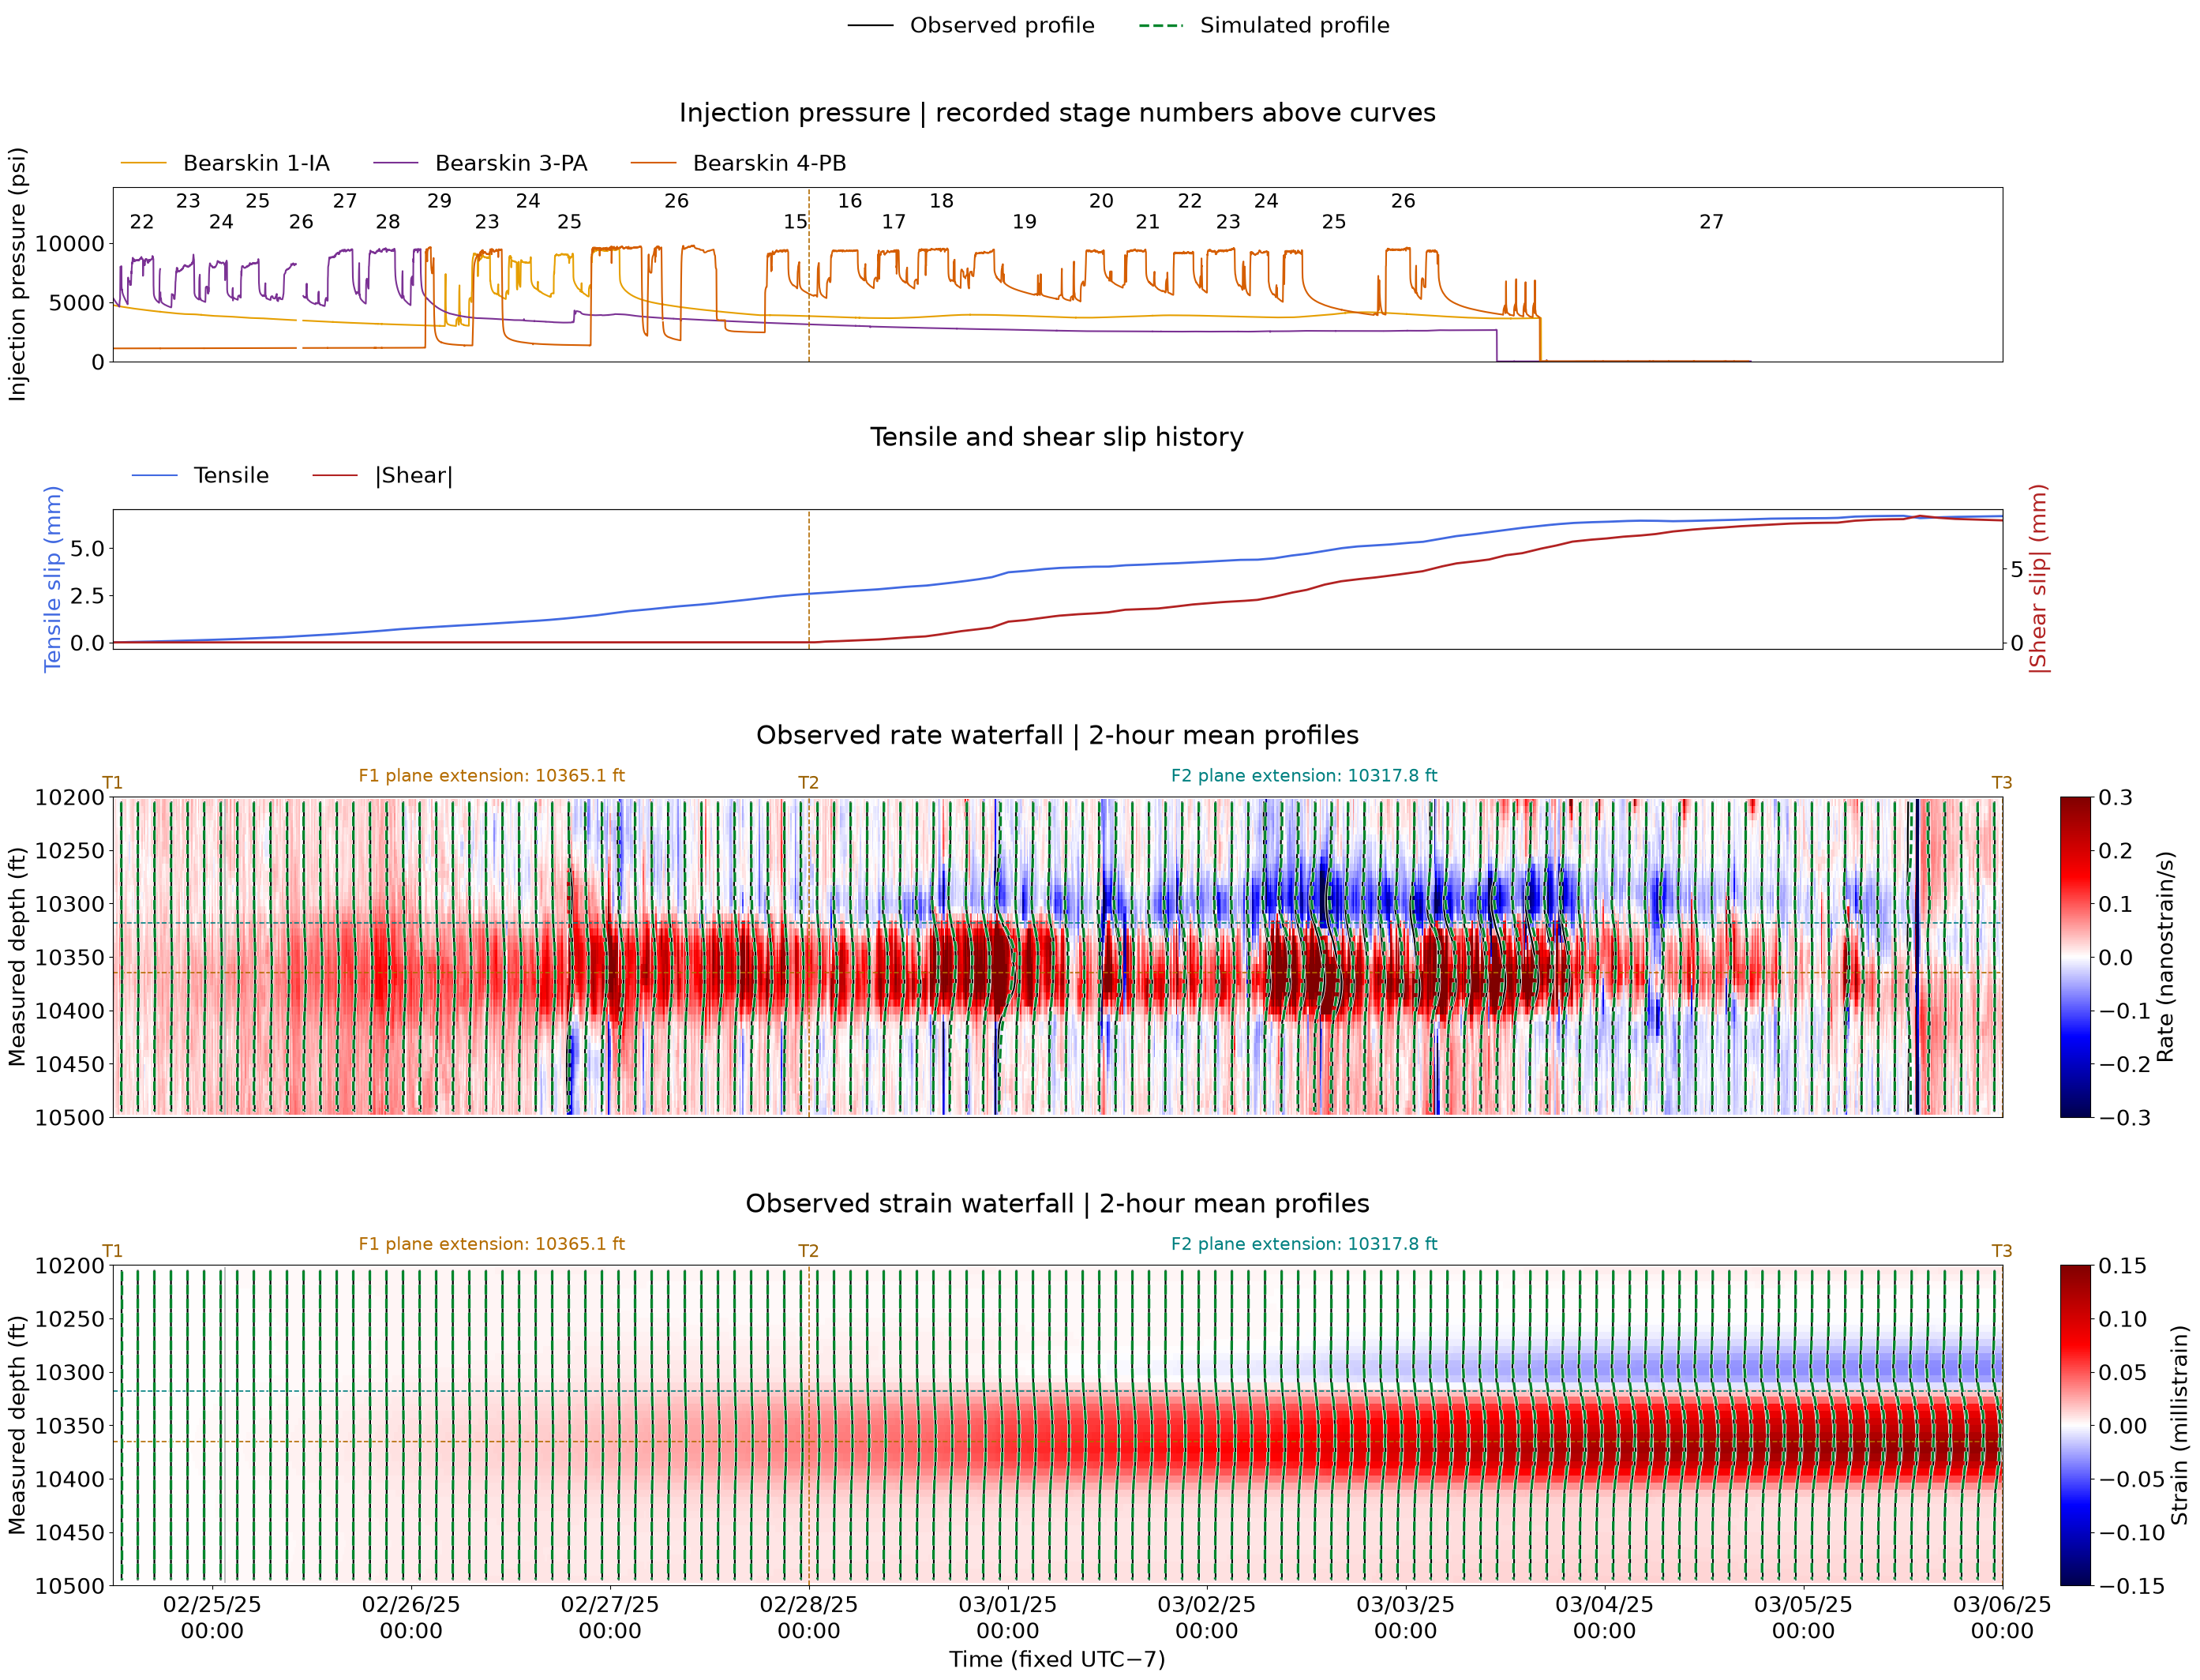

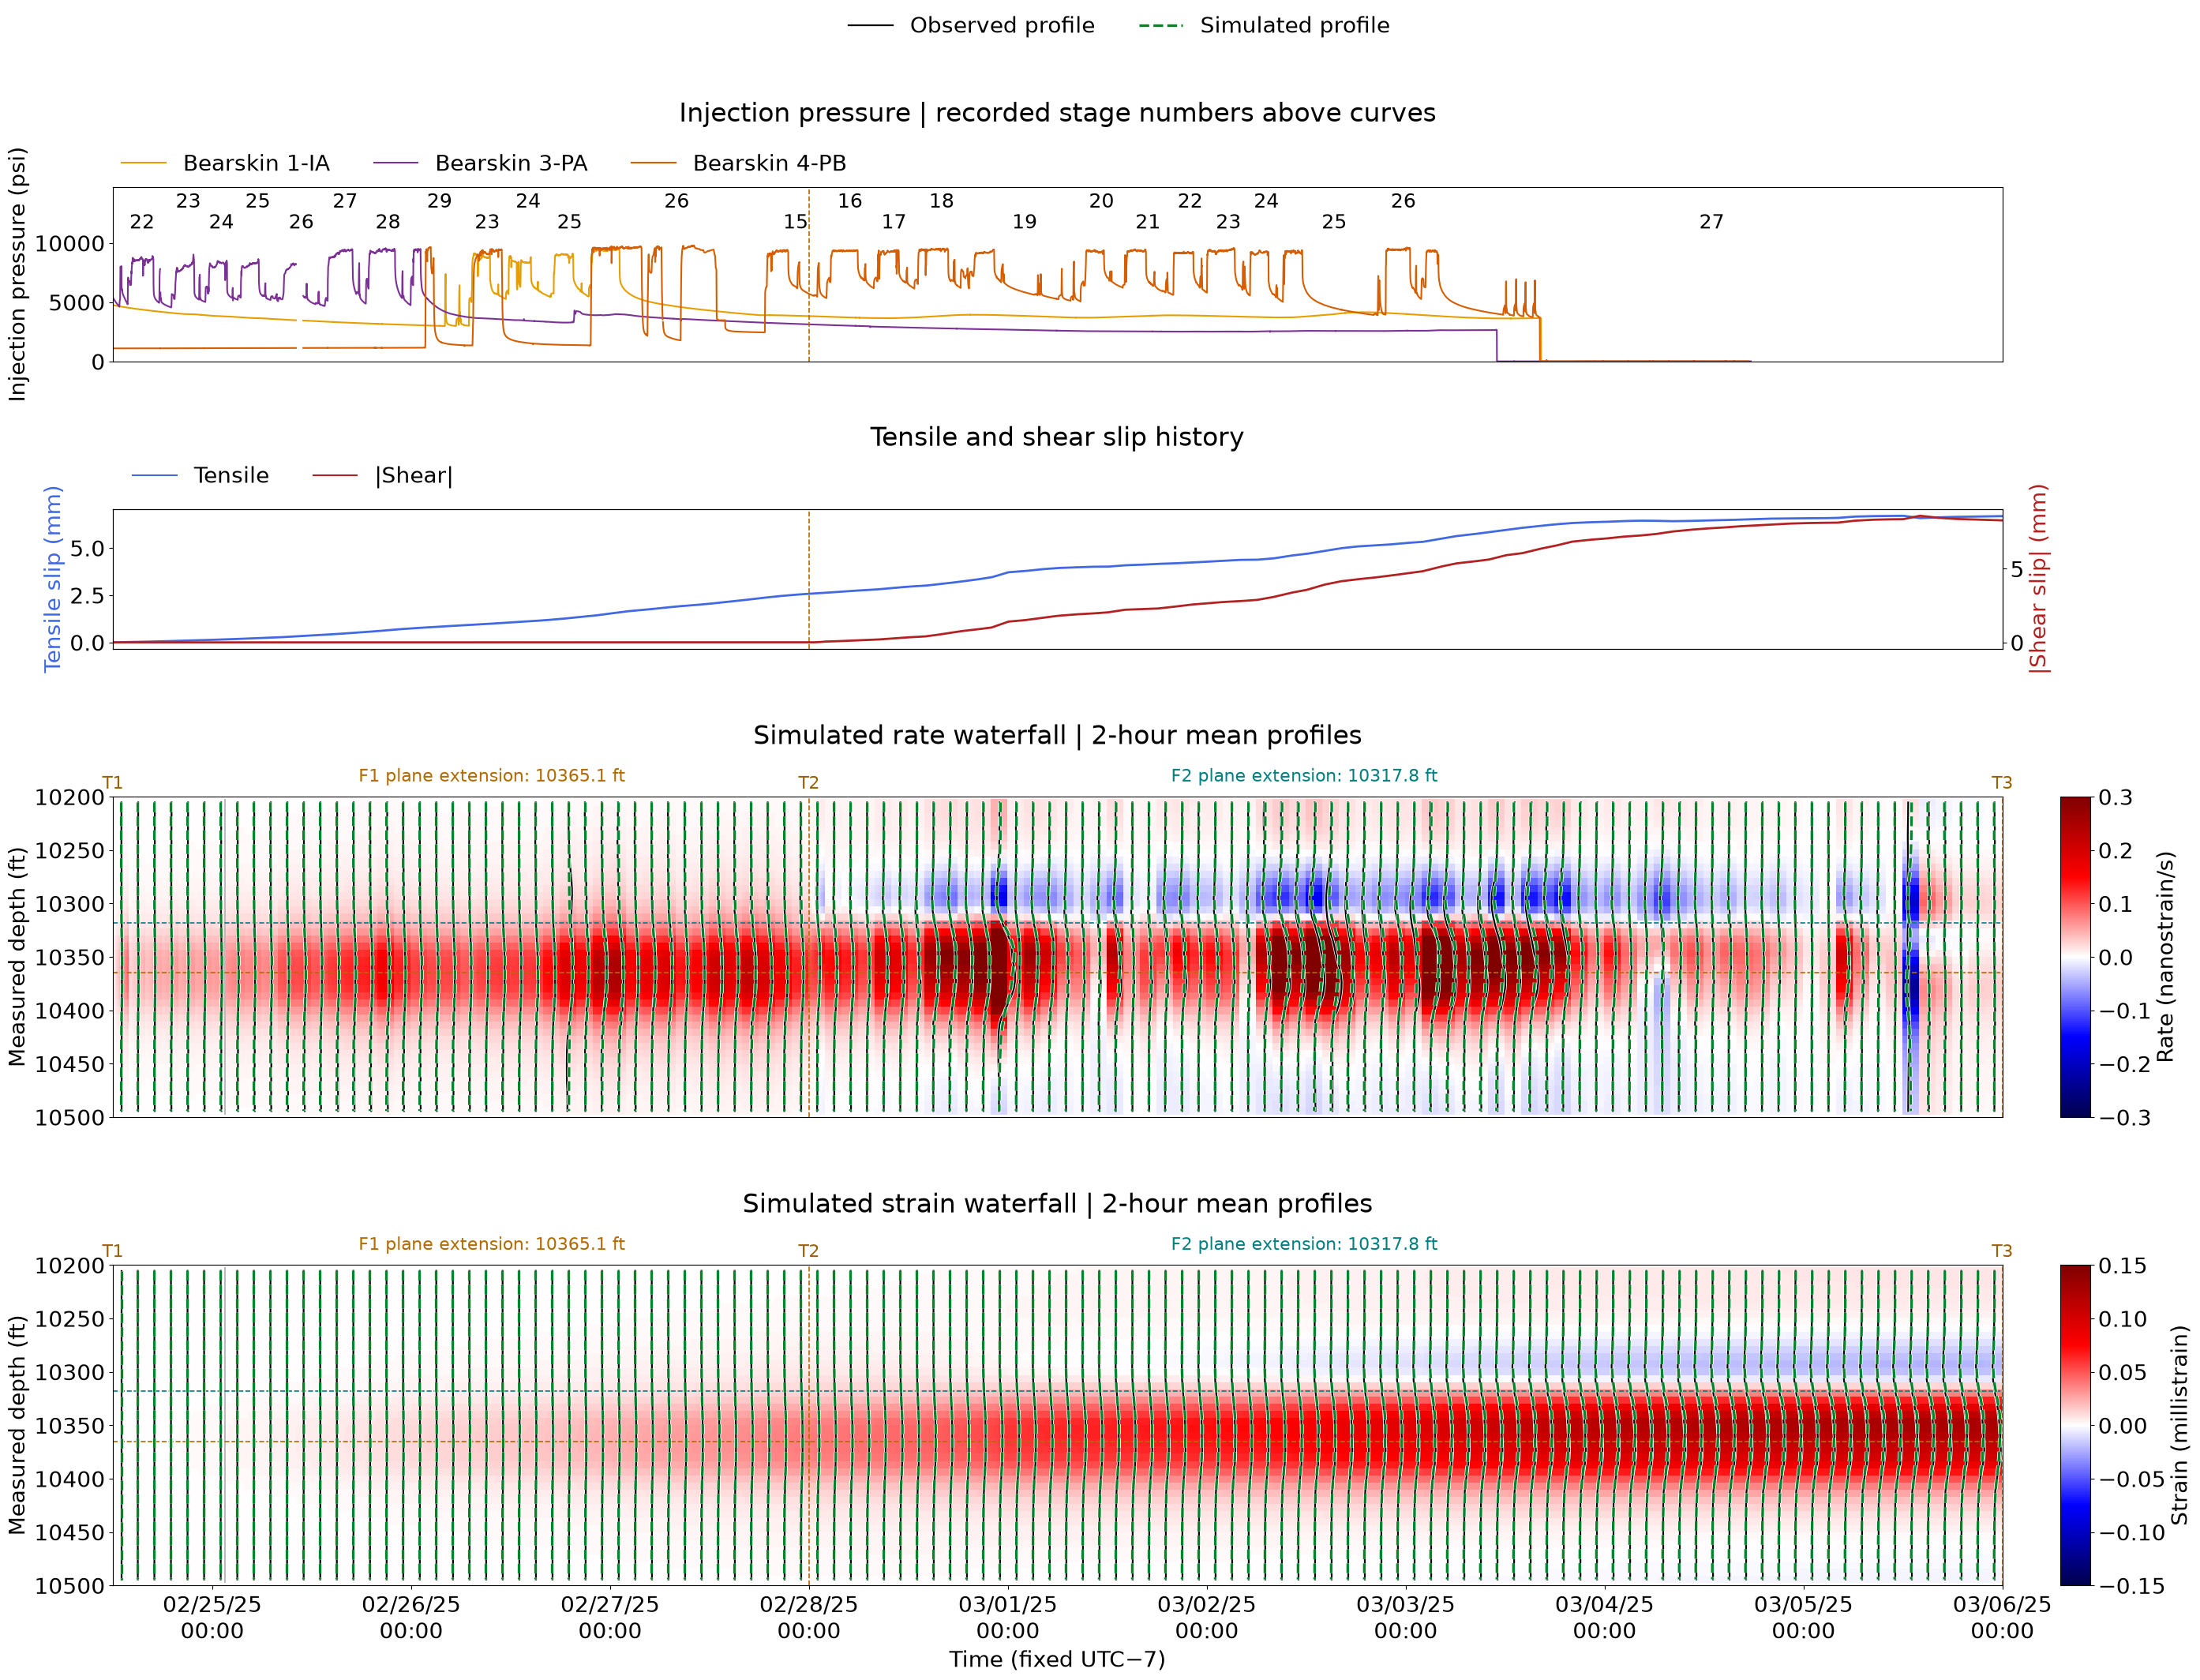

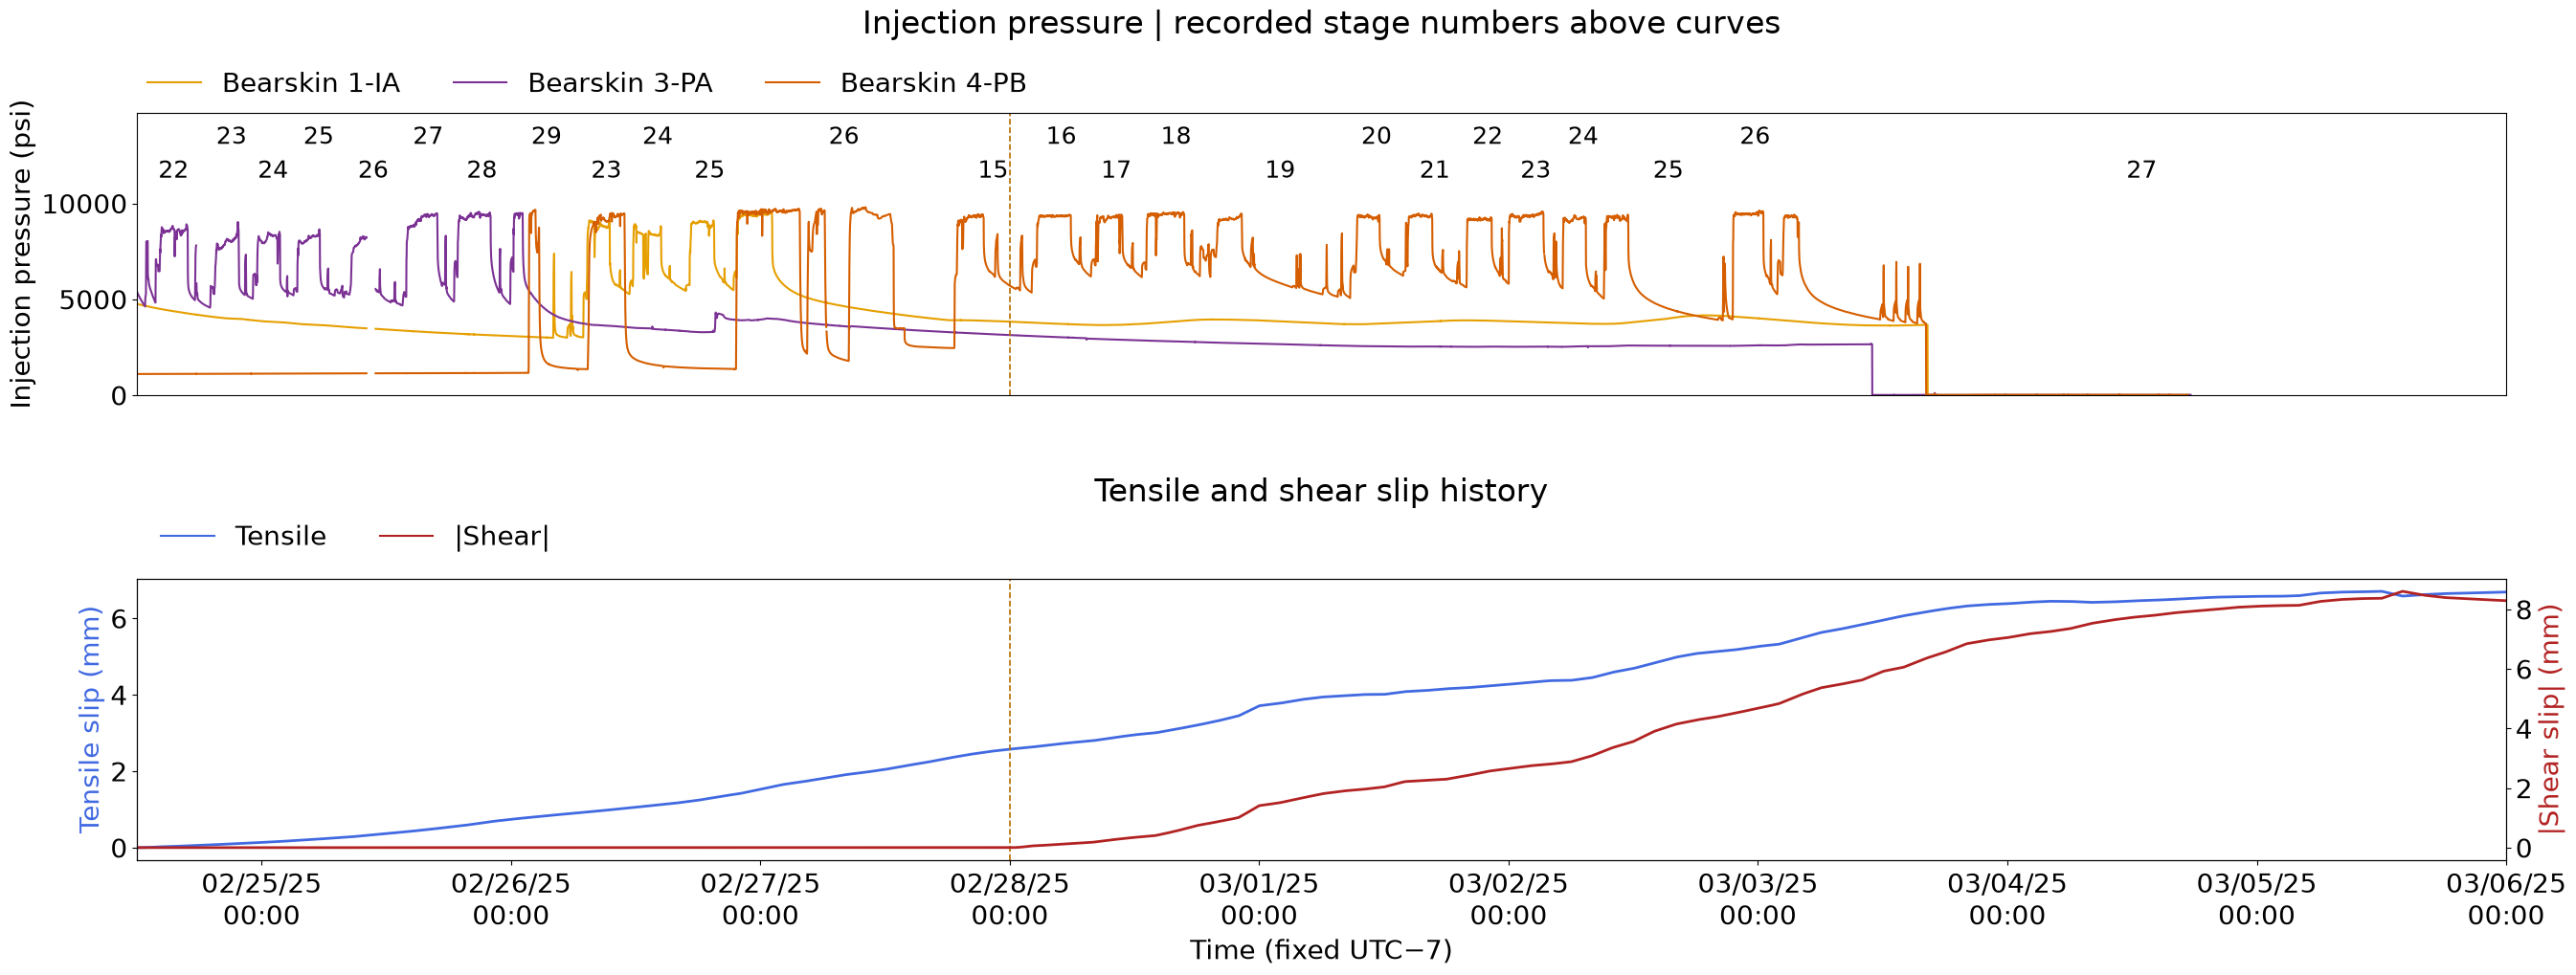

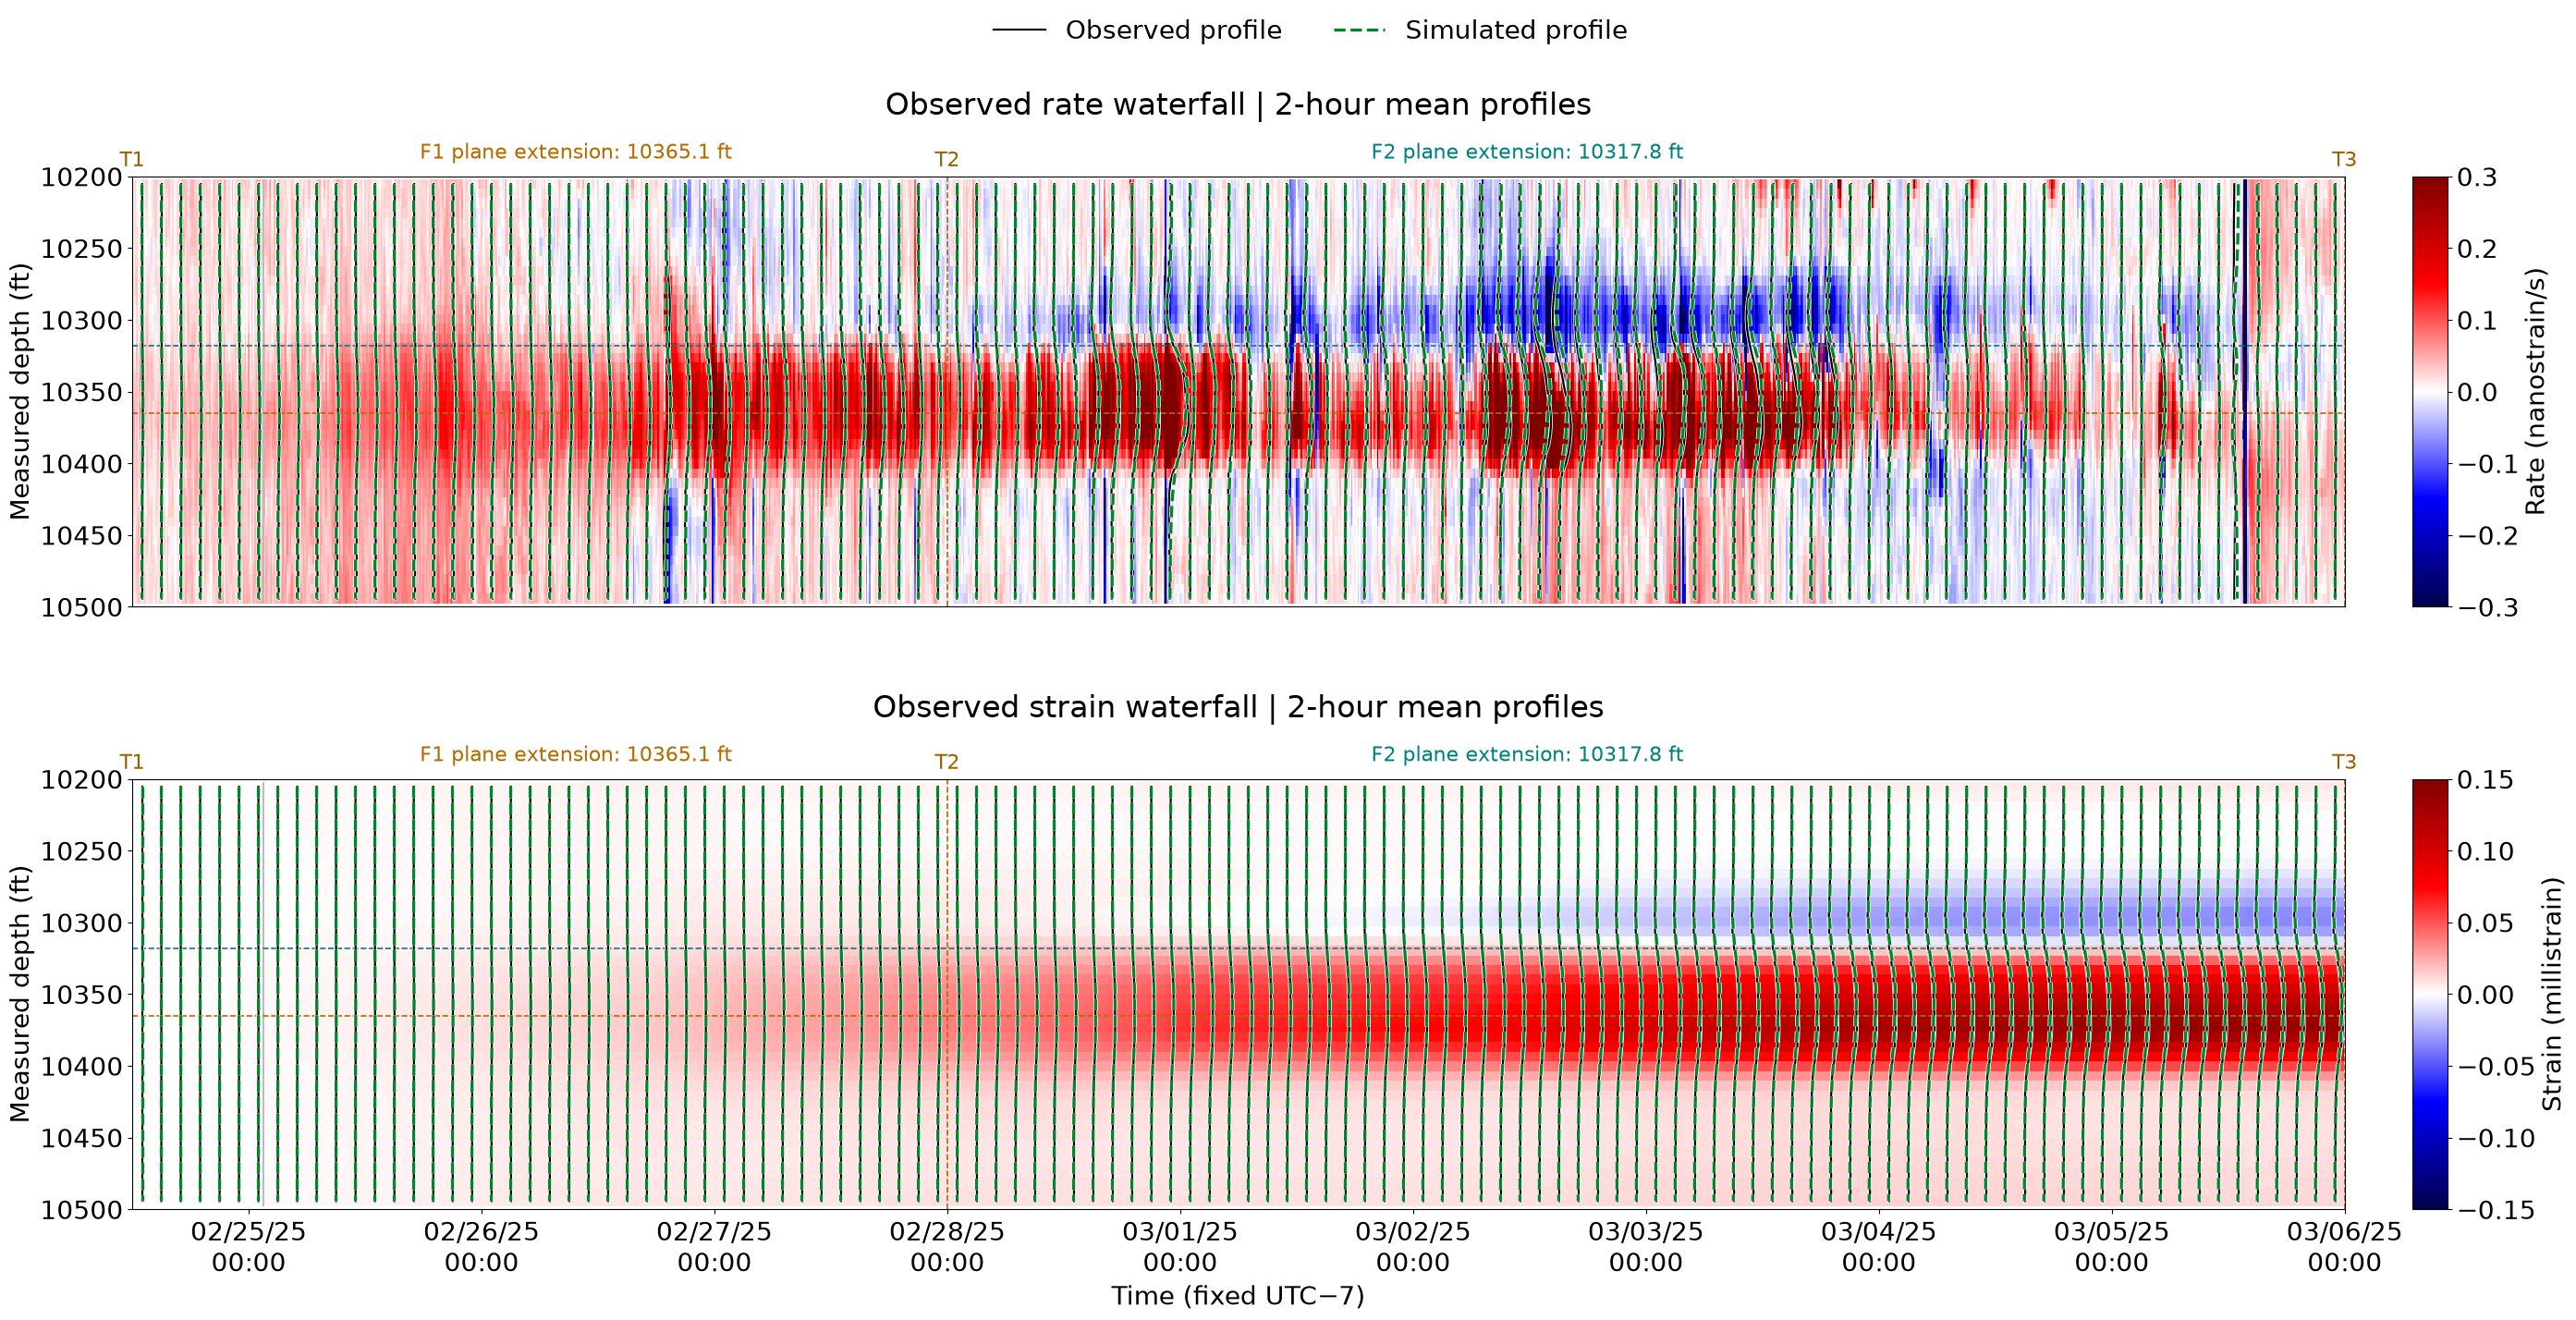

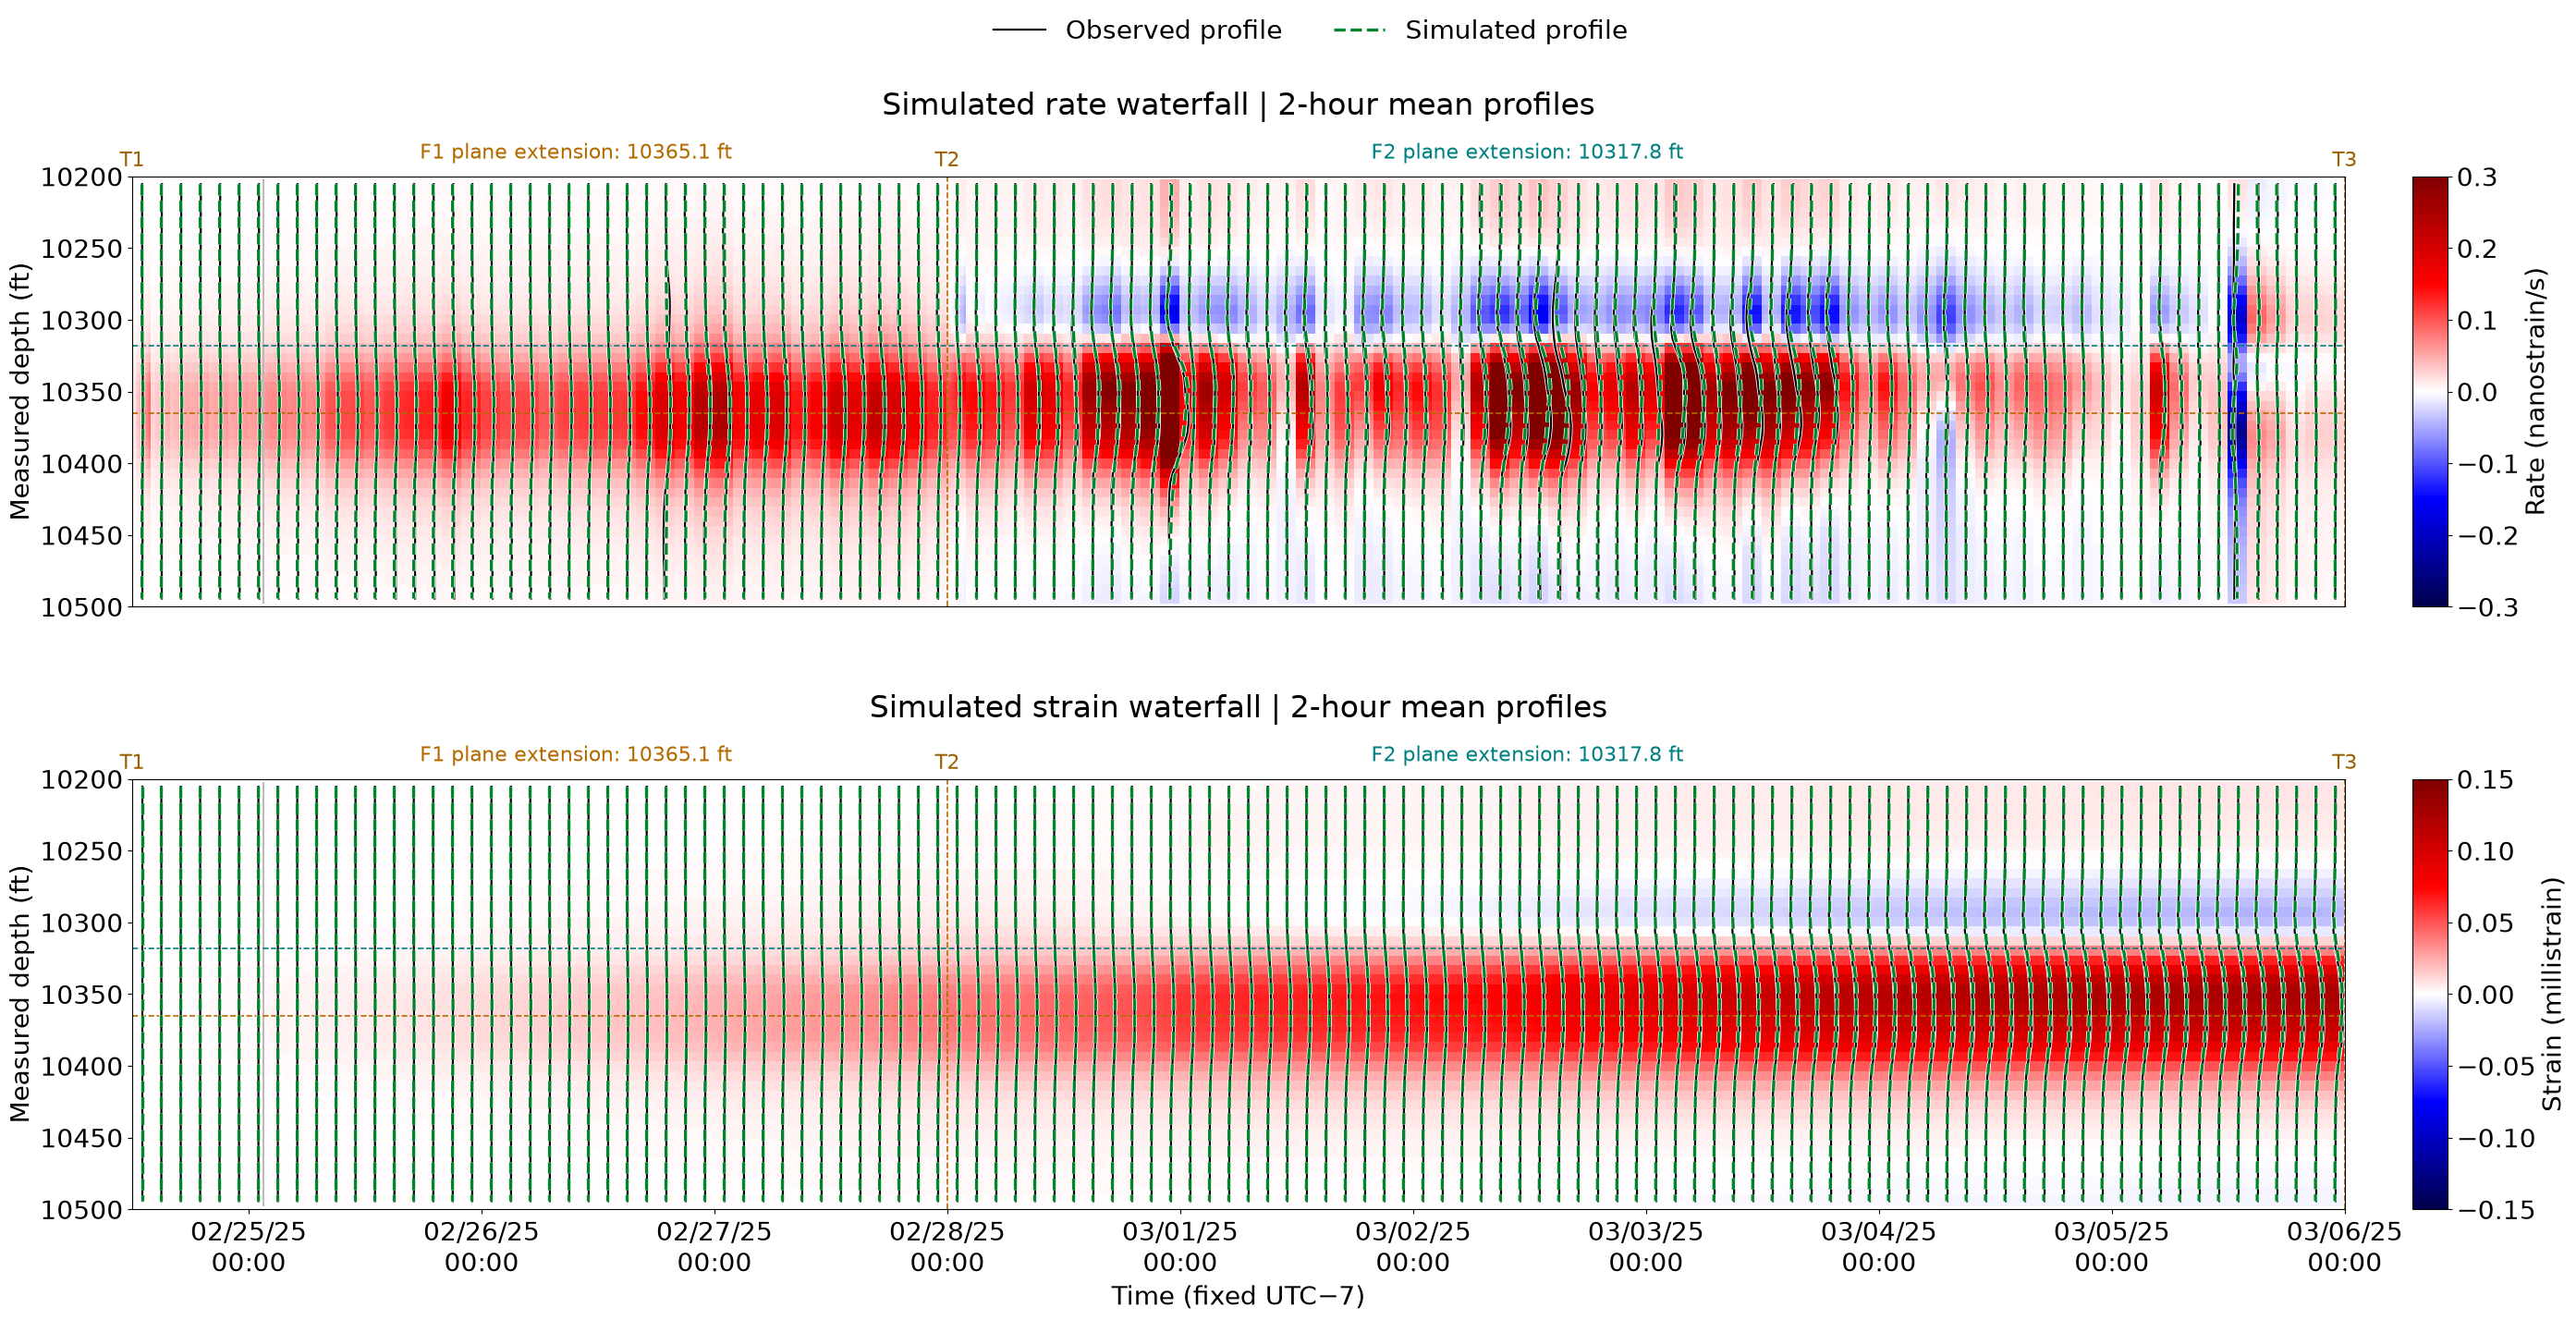

In [12]:
# Cell 14 | Modified 2026-09-20 22:37:10 MDT — Shared-axis pressure, slip and waterfall diagnostics
# Purpose: Show recorded pressure stages and slip alongside observed and simulated strain-rate/strain waterfalls.
injection=pd.read_csv(OUT/'injection_pressure.csv',parse_dates=['time'])
plot_summary(obs,final,injection,'Inverted_rate_fit_two_hour_slip_history')
plot_summary(obs,final,injection,'Inverted_rate_fit_two_hour_slip_history',background='simulated')
plot_pressure_slip(obs,final,injection,'Inverted_rate_fit_two_hour_slip_history')
plot_comparison(obs,final,'inverted')